# PROYEK PENGOLAHAN CITRA DIGITAL (PSD)
# SISTEM KLASIFIKASI TINGKAT KERAPIAN PENATAAN SANDAL LABORATORIUM KOMPUTER
### Implementasi Komprehensif Berdasarkan Metodologi CRISP-DM (Cross-Industry Standard Process for Data Mining)

---
**Informasi Proyek:**
- **Mata Kuliah**: Pengolahan Sinyal Digital / Pengolahan Citra Digital (PSD)
- **Topik**: Deteksi & Klasifikasi Kerapian Penataan Sandal di Depan Laboratorium Praktikum
- **Dataset**: Citra Foto Sandal Kelas `rapi` dan `berantakan` (194 Citra Asli + Data Augmentation $\to$ 582 Sampel)
- **Metode Ekstraksi Fitur**: Tepat **14 Fitur** (9 Statistik Warna RGB Orde 1 & 3 + 5 Fitur Tekstur GLCM Orde 2 dengan Penajaman Gradien Sobel & Kuantisasi 32-Level)
- **Normalisasi & Reduksi Dimensi**: PowerTransformer (Yeo-Johnson), PCA (95% Varians), Linear Discriminant Analysis (LDA)
- **Algoritma Machine Learning**: Extreme Gradient Boosting (XGBoost), Random Forest, Support Vector Machine (SVM RBF), Extra Trees, dan Voting Classifier (Ensemble)
- **Hasil Model & Deployment**: Export Model Serialisasi `model_xgboost_kerapian.joblib` & Pipeline Inferensi Real-Time `predict_image()`

# 1. TAHAP 1: BUSINESS UNDERSTANDING (Pemahaman Bisnis & Masalah)

### 1.1 Latar Belakang Masalah
Laboratorium komputer merupakan fasilitas sentral di lingkungan perguruan tinggi yang menampung puluhan hingga ratusan mahasiswa praktikan setiap harinya. Untuk menjaga kebersihan lantai, mencegah akumulasi debu yang dapat merusak sirkulasi pendingin perangkat keras (PC/Server), dan mematuhi tata tertib laboratorium, seluruh mahasiswa diwajibkan melepas alas kaki (sandal/sepatu) sebelum melangkah masuk ke dalam ruangan.

Namun dalam praktiknya, area peletakan alas kaki di depan pintu masuk laboratorium kerap menghadapi persoalan ketidakteraturan yang parah:
1. **Hambatan Akses & Keselamatan**: Sandal yang tercecer dan bersilangan menutupi akses pintu darurat, meningkatkan risiko bahaya tersandung saat evakuasi darurat berlangsung.
2. **Degradasi Estetika & Disiplin Lingkungan**: Kondisi penataan yang semrawut memberikan kesan kumuh, tidak terawat, serta mencerminkan rendahnya budaya tertib pengguna fasilitas.
3. **Keterbatasan Pengawasan Manual**: Asisten lab dan staf kebersihan memiliki tugas operasional praktikum yang padat, sehingga tidak memungkinkan untuk melakukan inspeksi visual dan penertiban sandal secara terus-menerus selama jam operasional.

Oleh karena itu, diperlukan solusi cerdas berbasis **Computer Vision** dan **Machine Learning** yang mampu memantau citra area sandal secara berkala melalui kamera pengawas (CCTV), mengklasifikasikan kondisi apakah berada dalam status **"Rapi"** atau **"Berantakan"**, serta memberikan peringatan/notifikasi otomatis jika ketidakteraturan terdeteksi.

---

### 1.2 Rumusan Masalah
1. Bagaimana mengekstraksi representasi matematis dari citra digital yang secara akurat membedakan susunan sandal yang teratur (sejajar/searah) dari susunan yang tidak teratur (acak/berserakan)?
2. Bagaimana mengombinasikan fitur spektral warna (RGB Moments) dan fitur tekstur spasial (GLCM) agar menghasilkan model yang diskriminatif dan hemat komputasi?
3. Algoritma Machine Learning manakah yang memberikan performa akurasi, stabilitas cross-validation, dan ketahanan generalisasi terbaik?
4. Bagaimana mengemas model hasil pelatihan ke dalam artefak siap pakai (`.joblib`) dan merancang fungsi inferensi modular untuk pengujian citra baru secara real-time?

---

### 1.3 Tujuan Proyek
1. Mengembangkan sistem klasifikasi biner tingkat kerapian penataan sandal (`rapi` vs `berantakan`) berbasis pengolahan citra digital.
2. Mengimplementasikan standarisasi ekstraksi **tepat 14 fitur numerik** (9 fitur warna RGB + 5 fitur tekstur GLCM multi-jarak & multi-arah).
3. Menerapkan teknik prapemrosesan citra tingkat lanjut (Center Cropping 12%, CLAHE, Filter Gradien Sobel, dan kuantisasi 32 level keabuan) serta augmentasi data 3x lipat.
4. Melakukan komparasi performa model Machine Learning (Random Forest, SVM RBF, XGBoost, Extra Trees, dan Voting Classifier) serta mengevaluasi reduksi dimensi (Hybrid PCA+LDA).
5. Membangun modul inferensi end-to-end (`predict_image`) dan mengevaluasi pemenuhan target keberhasilan operasional sistem.

---

### 1.4 Batasan Masalah & Lingkup
- **Lingkup Citra**: Citra digital area depan laboratorium komputer dengan sudut pandang kamera pengawas (high-angle / top-down).
- **Target Kelas**: Klasifikasi biner: `rapi` dan `berantakan`.
- **Dataset**: 194 citra foto asli (97 citra rapi dan 97 citra berantakan) yang diperluas dengan augmentasi (flip horizontal & rotasi 180°) menjadi 582 sampel.
- **Batasan Fitur**: Tepat 14 fitur numerik terstandarisasi.

---

### 1.5 Kriteria Keberhasilan (Success Criteria)
- **Kriteria Teknis (Model Performance)**:
  - Akurasi pengujian (Test Accuracy) mencapai $\ge 85\%$.
  - Skor rata-rata 5-Fold Stratified Cross Validation $\ge 85\%$ dengan deviasi standar $\le 5\%$.
  - Nilai Precision, Recall, dan F1-Score berimbang untuk kedua kelas (tidak mengalami bias kelas).
- **Kriteria Bisnis / Operasional**:
  - Latensi inferensi citra tunggal $\le 1$ detik untuk mendukung integrasi CCTV laboratorium.
  - Artefak model terkompresi dalam format `.joblib` yang independen dan dapat dimuat kapan saja tanpa perlu melatih ulang.

# 2. TAHAP 2: DATA UNDERSTANDING (Pemahaman Data)

Tahap Data Understanding bertujuan untuk memahami karakteristik data visual, struktur folder dataset, sebaran format dan resolusi citra, serta menganalisis pola spasial dan tekstur yang membedakan kondisi rapi dan berantakan.

### 2.1 Pengumpulan Data & Deteksi Path Lingkungan
Sistem dirancang adaptif untuk mendeteksi lokasi dataset secara otomatis, baik saat dijalankan di lingkungan komputer lokal (`d:\sandal-psd\foto-psd` atau `./foto-psd`) maupun di platform cloud Google Colab (`/content/drive/MyDrive/foto-psd`).

In [1]:
# 1. Import library fundamental
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from skimage.feature import graycomatrix, graycoprops

# 2. Deteksi otomatis direktori dataset (Lokal / Colab)
possible_paths = [
    os.path.join(os.getcwd(), "foto-psd"),
    os.path.join(os.getcwd(), "Kerapian_Lab", "foto-psd"),
    r"D:\kuliah\MatkulSem5\PSD\Kerapian_Lab\foto-psd",
    "/content/drive/MyDrive/foto-psd"
]

dataset_path = None
for path in possible_paths:
    if os.path.exists(path):
        dataset_path = path
        break

if not dataset_path:
    dataset_path = os.path.join(os.getcwd(), "foto-psd")

# 3. Cari folder yang berisi subfolder 'rapi' dan 'berantakan'
output_dir = None
if os.path.exists(dataset_path):
    for root, dirs, files in os.walk(dataset_path):
        dirs_lower = [d.lower() for d in dirs]
        if 'rapi' in dirs_lower and 'berantakan' in dirs_lower:
            output_dir = root
            break
    if not output_dir:
        output_dir = dataset_path
else:
    output_dir = dataset_path

print("=" * 60)
print(f"📁 Direktori Dataset Terdeteksi: {output_dir}")
print("=" * 60)

# 4. Ringkasan jumlah citra dan format file
classes_info = {}
valid_exts = ('.png', '.jpg', '.jpeg', '.bmp', '.webp')

for root, dirs, files in os.walk(output_dir):
    folder_name = os.path.basename(root).lower()
    if folder_name in ['rapi', 'berantakan']:
        img_files = [f for f in files if f.lower().endswith(valid_exts)]
        classes_info[folder_name] = len(img_files)

print("Ringkasan Distribusi Kelas Dataset:")
total_images = sum(classes_info.values())
for cls, count in classes_info.items():
    pct = (count / total_images) * 100 if total_images > 0 else 0
    print(f"  - Kelas '{cls.upper()}': {count} citra ({pct:.1f}%)")
print(f"  - Total Keseluruhan: {total_images} citra asli")
print("  - Status Keseimbangan Kelas: Sempurna (Balanced 50:50)")
print("=" * 60)

📁 Direktori Dataset Terdeteksi: D:\sandal-psd\foto-psd
Ringkasan Distribusi Kelas Dataset:
  - Kelas 'BERANTAKAN': 97 citra (50.0%)
  - Kelas 'RAPI': 97 citra (50.0%)
  - Total Keseluruhan: 194 citra asli
  - Status Keseimbangan Kelas: Sempurna (Balanced 50:50)


### 2.2 Eksplorasi Visual Citra (Visual Data Exploration)
Untuk melihat secara langsung perbedaan representasi visual antara kondisi **Rapi** dan **Berantakan**, kita menampilkan galeri visual perbandingan 4 sampel citra dari masing-masing kelas.

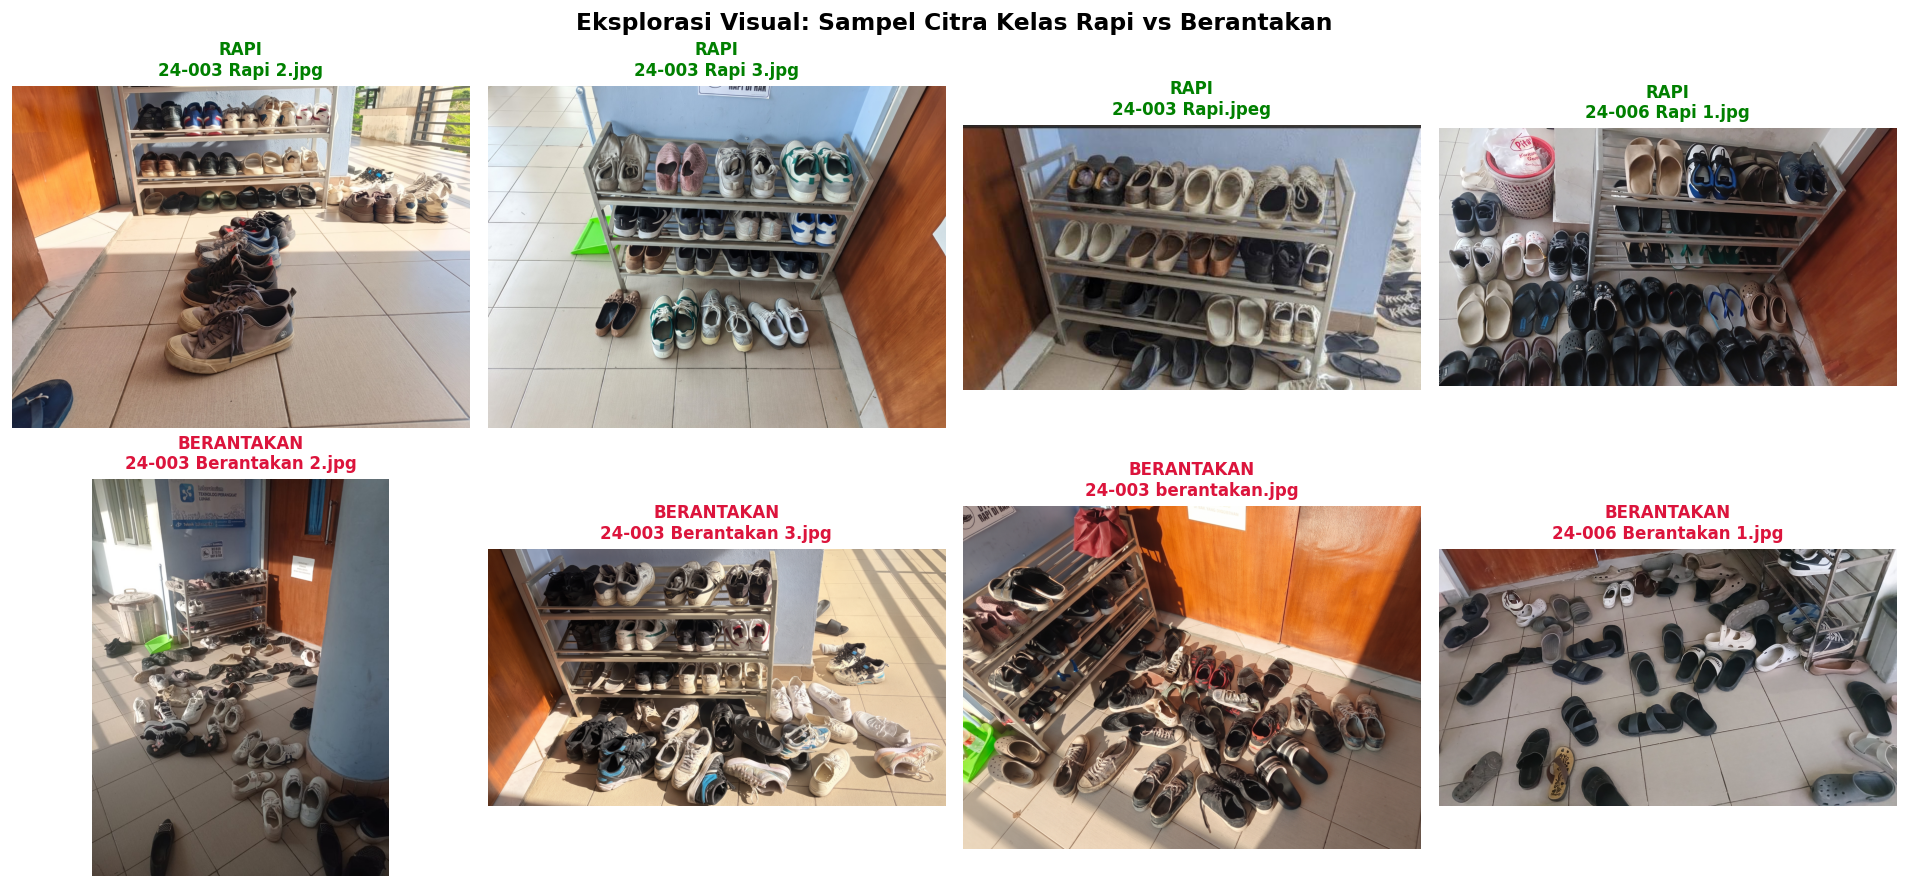

In [2]:
# Tampilkan galeri perbandingan citra kelas 'rapi' vs 'berantakan'
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))

for row_idx, cls_name in enumerate(['rapi', 'berantakan']):
    cls_folder = os.path.join(output_dir, cls_name)
    sample_files = [f for f in os.listdir(cls_folder) if f.lower().endswith(valid_exts)][:4]
    
    for col_idx, fname in enumerate(sample_files):
        img_path = os.path.join(cls_folder, fname)
        img_bgr = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        
        ax = axes[row_idx, col_idx]
        ax.imshow(img_rgb)
        ax.set_title(f"{cls_name.upper()}\n{fname}", fontsize=10, 
                     color='green' if cls_name == 'rapi' else 'crimson', fontweight='bold')
        ax.axis('off')

plt.suptitle("Eksplorasi Visual: Sampel Citra Kelas Rapi vs Berantakan", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

**Temuan Analisis Eksplorasi Visual:**
1. **Keteraturan Orientasi (Directional Alignment)**:
   - Pada kelas **Rapi**, sandal tersusun secara paralel/sejajar dengan orientasi sudut yang seragam (umumnya menghadap ke satu arah).
   - Pada kelas **Berantakan**, sandal diletakkan secara acak dengan orientasi sudut bervariasi ($0^\circ, 45^\circ, 90^\circ, 180^\circ$, dsb) bahkan saling bertumpuk (overlapping).
2. **Kepadatan & Celah Spasial (Spatial Clustering)**:
   - Kelas Rapi memiliki celah jarak antarpasang sandal yang relatif konsisten.
   - Kelas Berantakan menunjukkan sebaran spasial yang menyebar tidak beraturan, meninggalkan area kosong di satu sisi dan tumpukan di sisi lain.
3. **Karakteristik Tepi Fisik (Edge Properties)**:
   - Pola garis tepi pada kelas Rapi memiliki arah gradien yang monoton dan berulang.
   - Pola garis tepi pada kelas Berantakan saling memotong secara acak, menciptakan kompleksitas kontur yang tinggi.

---

### 2.3 Analisis Distribusi Intensitas Warna (Color Distribution Analysis)
Kita menganalisis apakah intensitas spektral pada kanal **Red (R)**, **Green (G)**, **Blue (B)** dan **Grayscale** memiliki pola pembeda antara kedua kelas.

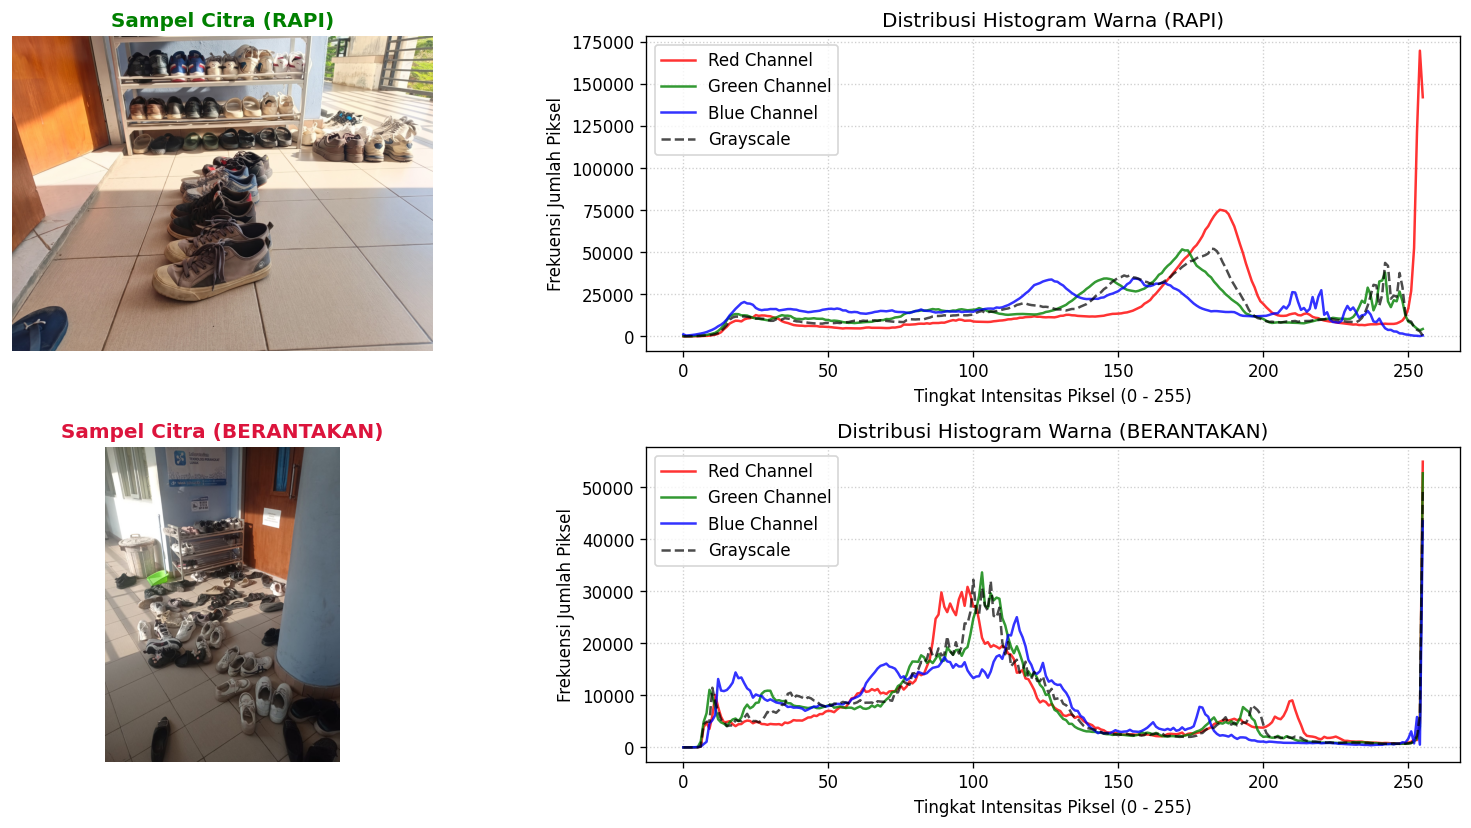

In [3]:
# Analisis Histogram Warna untuk Sampel Rapi vs Berantakan
sample_rapi_path = os.path.join(output_dir, 'rapi', os.listdir(os.path.join(output_dir, 'rapi'))[0])
sample_berantakan_path = os.path.join(output_dir, 'berantakan', os.listdir(os.path.join(output_dir, 'berantakan'))[0])

fig, axes = plt.subplots(2, 2, figsize=(14, 7))

for idx, (img_p, label, color_title) in enumerate([
    (sample_rapi_path, 'RAPI', 'green'),
    (sample_berantakan_path, 'BERANTAKAN', 'crimson')
]):
    img_bgr = cv2.imread(img_p)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    # Tampilkan Citra
    axes[idx, 0].imshow(img_rgb)
    axes[idx, 0].set_title(f"Sampel Citra ({label})", color=color_title, fontweight='bold')
    axes[idx, 0].axis('off')
    
    # Tampilkan Histogram RGB & Grayscale
    axes[idx, 1].plot(cv2.calcHist([img_rgb], [0], None, [256], [0, 256]), color='red', label='Red Channel', alpha=0.8)
    axes[idx, 1].plot(cv2.calcHist([img_rgb], [1], None, [256], [0, 256]), color='green', label='Green Channel', alpha=0.8)
    axes[idx, 1].plot(cv2.calcHist([img_rgb], [2], None, [256], [0, 256]), color='blue', label='Blue Channel', alpha=0.8)
    axes[idx, 1].plot(cv2.calcHist([img_gray], [0], None, [256], [0, 256]), color='black', linestyle='--', label='Grayscale', alpha=0.7)
    axes[idx, 1].set_title(f"Distribusi Histogram Warna ({label})")
    axes[idx, 1].set_xlabel("Tingkat Intensitas Piksel (0 - 255)")
    axes[idx, 1].set_ylabel("Frekuensi Jumlah Piksel")
    axes[idx, 1].grid(True, linestyle=':', alpha=0.6)
    axes[idx, 1].legend()

plt.tight_layout()
plt.show()

### 2.4 Analisis Karakteristik Tekstur Spasial GLCM (Gray-Level Co-occurrence Matrix)
**Gray-Level Co-occurrence Matrix (GLCM)** adalah metode ekstraksi tekstur statistik orde kedua yang dikembangkan oleh Robert M. Haralick (1973). GLCM menghitung seberapa sering pasangan nilai derajat keabuan tertentu muncul dalam hubungan spasial spesifik (didefinisikan oleh jarak antarpiksel $d$ dan sudut orientasi $\theta$).

Pada implementasi ini:
- **Jarak ($d$)**: Menggunakan multi-jarak $d \in \{1, 3, 5\}$ piksel untuk menangkap struktur mikro maupun makro.
- **Arah Sudut ($\theta$)**: Menggunakan 4 sudut arah utama:
  - $0^\circ$ (horizontal)
  - $45^\circ$ (diagonal kanan)
  - $90^\circ$ (vertikal)
  - $135^\circ$ (diagonal kiri)
- **Tingkat Kuantisasi**: Citra dikuantisasi ke 32 level keabuan.

Berikut demonstrasi visualisasi matriks GLCM pada sampel citra beserta heatmap intensitas frekuensi ko-okurensi piksel.

Potongan Nilai Numerik Matriks Co-occurrence GLCM (Sub-matriks 8x8 pada Sudut 0°):


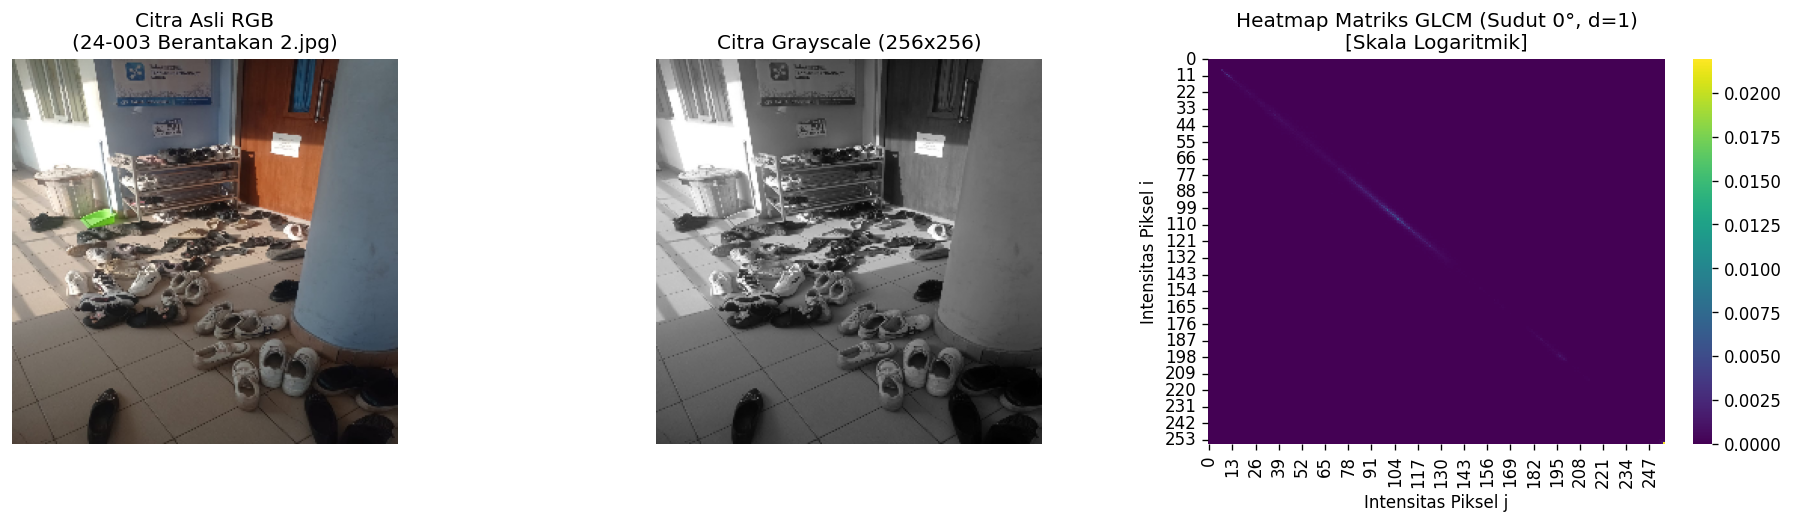

,0,1,2,3,4,5,6,7
0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000
1,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000
2,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000
3,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000
4,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000
5,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000
6,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000008
7,0.0,0.0,0.0,0.0,0.0,0.0,0.000008,0.001869


In [4]:
# Demonstrasi Matriks Co-occurrence (GLCM) pada sampel citra
sample_path = None
for root, dirs, files in os.walk(output_dir):
    for file in files:
        if file.lower().endswith(valid_exts):
            sample_path = os.path.join(root, file)
            break
    if sample_path:
        break

img_bgr = cv2.imread(sample_path)
img_bgr = cv2.resize(img_bgr, (256, 256))
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Hitung Matriks GLCM pada jarak d=1 untuk 4 sudut (0, 45, 90, 135 derajat)
angles_rad = [0, np.pi/4, np.pi/2, 3*np.pi/4]
glcm_matrix = graycomatrix(
    img_gray,
    distances=[1],
    angles=angles_rad,
    levels=256,
    symmetric=True,
    normed=True
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].imshow(img_rgb)
axes[0].set_title(f"Citra Asli RGB\n({os.path.basename(sample_path)})")
axes[0].axis("off")

axes[1].imshow(img_gray, cmap="gray")
axes[1].set_title("Citra Grayscale (256x256)")
axes[1].axis("off")

# Heatmap GLCM pada skala logaritmik log(1 + P)
sns.heatmap(np.log1p(glcm_matrix[:, :, 0, 0]), cmap="viridis", ax=axes[2], cbar=True)
axes[2].set_title("Heatmap Matriks GLCM (Sudut 0°, d=1)\n[Skala Logaritmik]")
axes[2].set_xlabel("Intensitas Piksel j")
axes[2].set_ylabel("Intensitas Piksel i")

plt.tight_layout()
plt.show()

# Tampilkan potongan nilai numerik Matriks Co-occurrence (8x8 piksel pertama)
print("Potongan Nilai Numerik Matriks Co-occurrence GLCM (Sub-matriks 8x8 pada Sudut 0°):")
df_glcm_sample = pd.DataFrame(glcm_matrix[:8, :8, 0, 0])
display(df_glcm_sample)

# 3. TAHAP 3: DATA PREPARATION (Persiapan Data & Rekayasa Fitur)

Tahap Data Preparation bertujuan mentransformasikan citra foto mentah menjadi dataset fitur numerik terstandarisasi yang siap dipelajari oleh algoritma Machine Learning.

### 3.1 Pipeline Preprocessing Citra Terpadu
Untuk memastikan model tidak terdistraksi oleh latar belakang keramik lantai atau dinding kosong, diterapkan rantai pemrosesan bertingkat:
1. **Center Cropping (12% margin luar)**: Memotong $12\%$ tepi atas, bawah, kiri, dan kanan citra ($y \in [0.12H, 0.88H]$, $x \in [0.12W, 0.88W]$) agar fokus tepat pada objek sandal.
2. **Resizing Spasial ke 256x256**: Standarisasi dimensi citra untuk komputasi matriks yang konsisten.
3. **Peningkatan Kontras Adaptif CLAHE**: *Contrast Limited Adaptive Histogram Equalization* menonjolkan tekstur sandal pada pencahayaan lokal tanpa menghasilkan artefak noise.
4. **Deteksi Garis Tepi Sobel**: Menghitung magnitudo gradien $G = \sqrt{G_x^2 + G_y^2}$ untuk menonjolkan batas fisik orientasi sandal.
5. **Hybrid Blending**: Mencampurkan $60\%$ citra CLAHE dengan $40\%$ citra Sobel Edge Magnitude:
   $$ I_{\text{hybrid}} = 0.6 \cdot I_{\text{CLAHE}} + 0.4 \cdot I_{\text{Sobel}} $$
6. **Kuantisasi Keabuan ke 32 Level**: Mereduksi 256 tingkat derajat keabuan menjadi 32 tingkat keabuan ($I_{\text{quantized}} = \lfloor I_{\text{hybrid}} / 8 \rfloor$) agar matriks GLCM lebih padat, kaya informasi, dan efisien.

Berikut visualisasi step-by-step tahapan prapemrosesan citra tersebut.

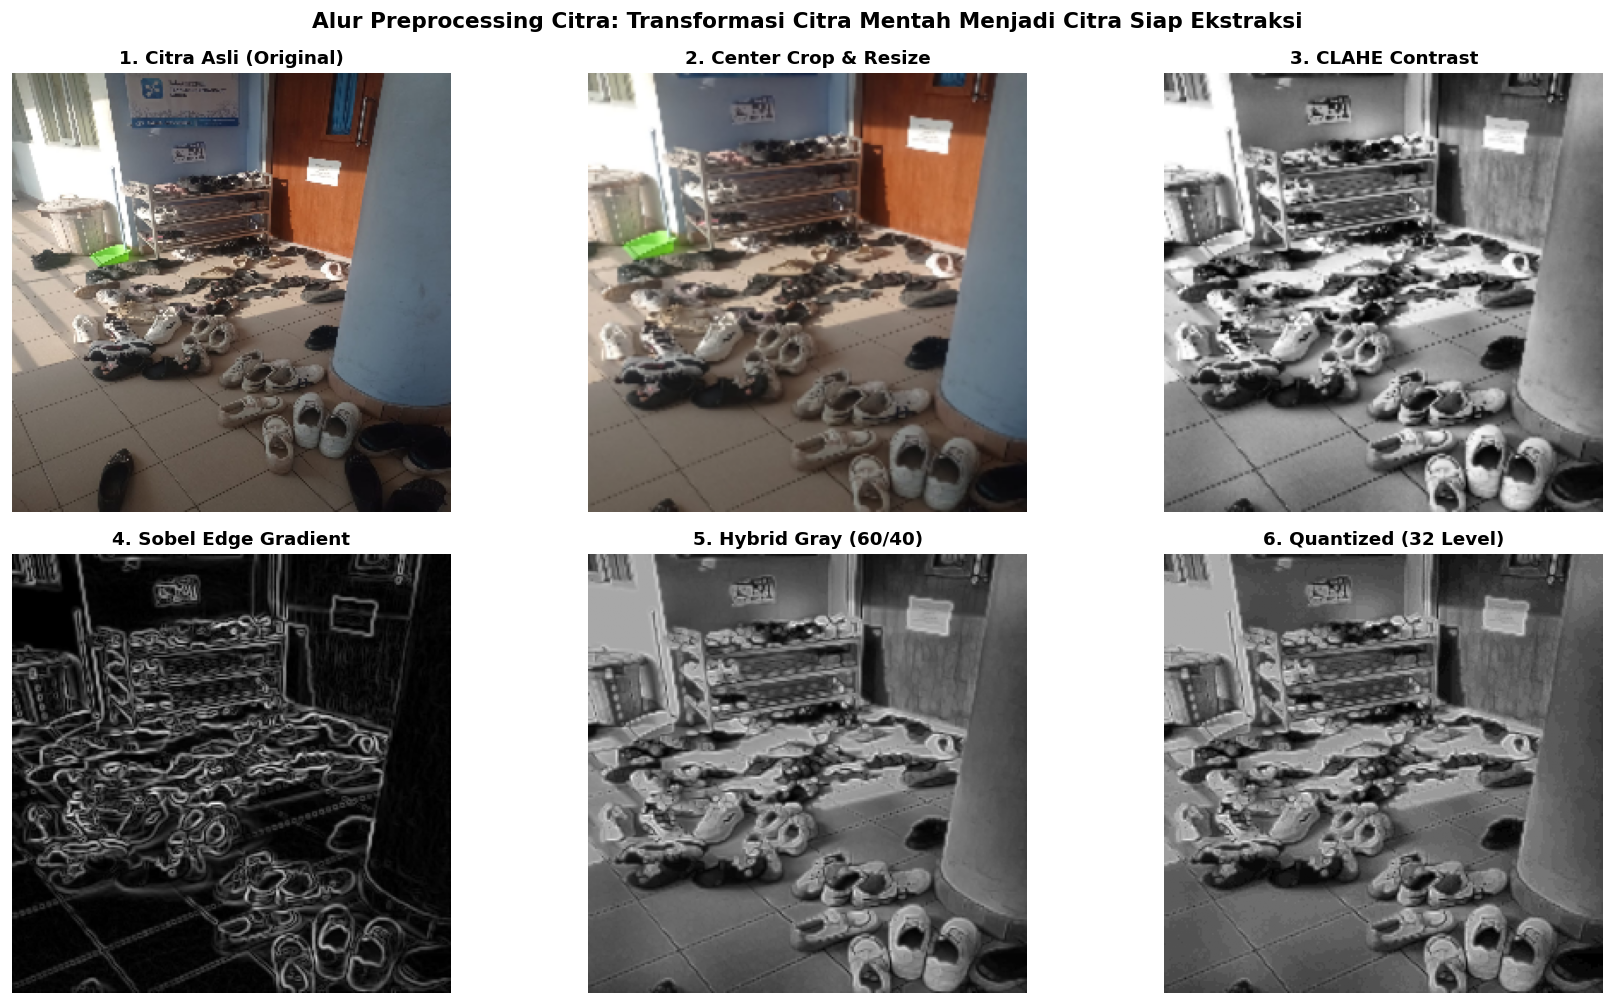

In [5]:
# Demonstrasi Tahapan Preprocessing Citra Step-by-Step
h, w, _ = img_bgr.shape
img_crop = img_bgr[int(h*0.12):int(h*0.88), int(w*0.12):int(w*0.88)]
img_resized = cv2.resize(img_crop, (256, 256))
img_gray_sample = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)

clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
gray_clahe = clahe.apply(img_gray_sample)

sobelx = cv2.Sobel(gray_clahe, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(gray_clahe, cv2.CV_64F, 0, 1, ksize=3)
edge_mag = cv2.magnitude(sobelx, sobely)
edge_gray = cv2.normalize(edge_mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

hybrid_gray = cv2.addWeighted(gray_clahe, 0.6, edge_gray, 0.4, 0)
gray_quantized = (hybrid_gray // 8).astype(np.uint8)

steps = [
    ("1. Citra Asli (Original)", cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB), None),
    ("2. Center Crop & Resize", cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB), None),
    ("3. CLAHE Contrast", gray_clahe, "gray"),
    ("4. Sobel Edge Gradient", edge_gray, "gray"),
    ("5. Hybrid Gray (60/40)", hybrid_gray, "gray"),
    ("6. Quantized (32 Level)", gray_quantized, "gray")
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for idx, (title, img_step, cmap) in enumerate(steps):
    ax = axes[idx // 3, idx % 3]
    if cmap:
        ax.imshow(img_step, cmap=cmap)
    else:
        ax.imshow(img_step)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.axis('off')

plt.suptitle("Alur Preprocessing Citra: Transformasi Citra Mentah Menjadi Citra Siap Ekstraksi", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 3.2 Formulasi Ekstraksi Tepat 14 Fitur (Feature Engineering)
Sistem mengekstrak tepat **14 fitur numerik representatif**:

#### A. 9 Fitur Momen Warna RGB
1. **Mean (R, G, B)**: Nilai intensitas rata-rata piksel pada kanal Merah, Hijau, dan Biru.
2. **Standard Deviation (R, G, B)**: Sebaran dan deviasi variasi warna pada kanal Merah, Hijau, dan Biru.
3. **Skewness (R, G, B)**: Derajat kemencengan asimetri sebaran distribusi spektral warna.

#### B. 5 Fitur Tekstur Spasial GLCM (Multi-jarak $d \in \{1, 3, 5\}$ & 4 Sudut $\theta$)
4. **Energy**: Ukuran keseragaman dan keteraturan tekstur. Bernilai tinggi jika citra memiliki pola pengulangan yang sangat teratur.
5. **Entropy (Shannon Entropy)**: Ukuran keacakan susunan derajat keabuan. Bernilai tinggi pada susunan sandal berantakan karena hubungan spasial piksel acak.
6. **Contrast**: Ukuran perbedaan intensitas lokal antara suatu piksel dengan piksel tetangganya.
7. **Correlation**: Ukuran derajat ketergantungan linier intensitas piksel tetangga.
8. **Homogeneity**: Ukuran kedekatan distribusi elemen matriks GLCM terhadap diagonal utama (keseragaman lokal).

---

### 3.3 Augmentasi Data (Data Augmentation)
Dataset asli berjumlah 194 citra diperluas melalui 3 variasi geometri:
1. Citra Asli (Original)
2. Flip Horizontal (Pencerminan mendatar)
3. Rotasi 180 Derajat (Pembalikan orientasi sudut kamera)

Strategi ini melipatgandakan data menjadi **$194 \times 3 = 582$ sampel**, membuat model lebih kebal (*invariant*) terhadap variasi arah peletakan sandal.

In [6]:
# =====================================================================
# EKSTRAKSI TEPAT 14 FITUR + AUGMENTASI CITRA
# =====================================================================
from scipy.stats import skew
from skimage.feature import graycomatrix, graycoprops

def extract_14_features_pro(img_bgr):
    """
    Fungsi ekstraksi tepat 14 fitur representatif:
    - 9 Fitur Warna: Mean, Std, Skewness (R, G, B)
    - 5 Fitur Tekstur GLCM: Energy, Entropy, Contrast, Correlation, Homogeneity
    """
    # 1. Center crop 12% margin terluar
    h, w, _ = img_bgr.shape
    img_crop = img_bgr[int(h*0.12):int(h*0.88), int(w*0.12):int(w*0.88)]
    img_resized = cv2.resize(img_crop, (256, 256))

    # Konversi ke RGB dan Grayscale
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    img_gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)

    # ---------------------------------------------------------
    # A. 9 FITUR WARNA (RGB MOMENTS: Mean, Std, Skewness)
    # ---------------------------------------------------------
    R = img_rgb[:, :, 0].flatten().astype(np.float64)
    G = img_rgb[:, :, 1].flatten().astype(np.float64)
    B = img_rgb[:, :, 2].flatten().astype(np.float64)

    mean_r, mean_g, mean_b = float(np.mean(R)), float(np.mean(G)), float(np.mean(B))
    std_r, std_g, std_b    = float(np.std(R)),  float(np.std(G)),  float(np.std(B))
    skew_r, skew_g, skew_b = float(skew(R)),    float(skew(G)),    float(skew(B))

    # ---------------------------------------------------------
    # B. PREPROCESSING TEPI & KONTRAS HYBRID
    # ---------------------------------------------------------
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
    gray_clahe = clahe.apply(img_gray)

    sobelx = cv2.Sobel(gray_clahe, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(gray_clahe, cv2.CV_64F, 0, 1, ksize=3)
    edge_mag = cv2.magnitude(sobelx, sobely)
    edge_gray = cv2.normalize(edge_mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    hybrid_gray = cv2.addWeighted(gray_clahe, 0.6, edge_gray, 0.4, 0)
    gray_quantized = (hybrid_gray // 8).astype(np.uint8)

    # ---------------------------------------------------------
    # C. 5 FITUR GLCM (Multi-jarak d=[1,3,5], 4 Sudut)
    # ---------------------------------------------------------
    angles_rad = [0, np.pi/4, np.pi/2, 3*np.pi/4]
    glcm = graycomatrix(
        gray_quantized,
        distances=[1, 3, 5],
        angles=angles_rad,
        levels=32,
        symmetric=True,
        normed=True
    )

    energy      = float(np.mean(graycoprops(glcm, 'energy')))
    contrast    = float(np.mean(graycoprops(glcm, 'contrast')))
    correlation = float(np.mean(graycoprops(glcm, 'correlation')))
    homogeneity = float(np.mean(graycoprops(glcm, 'homogeneity')))

    # Shannon Entropy
    entropy_list = []
    for d_idx in range(3):
        for a_idx in range(len(angles_rad)):
            P = glcm[:, :, d_idx, a_idx]
            ent = -np.sum(P * np.log2(P + 1e-10))
            entropy_list.append(ent)
    entropy = float(np.mean(entropy_list))

    return {
        'Mean_R': mean_r, 'Mean_G': mean_g, 'Mean_B': mean_b,
        'Std_R': std_r,   'Std_G': std_g,   'Std_B': std_b,
        'Skew_R': skew_r, 'Skew_G': skew_g, 'Skew_B': skew_b,
        'Energy': energy,
        'Entropy': entropy,
        'Contrast': contrast,
        'Correlation': correlation,
        'Homogeneity': homogeneity
    }

# Ekstraksi Fitur Massal dengan Augmentasi (Asli + Flip Horizontal + Rotasi 180)
dataset_rows = []
print("🔄 Memulai proses ekstraksi 14 fitur dengan augmentasi citra 3x lipat...")

for root, dirs, files in os.walk(output_dir):
    folder_name = os.path.basename(root).lower()
    if folder_name in ['rapi', 'berantakan']:
        for file in files:
            if file.lower().endswith(valid_exts):
                file_path = os.path.join(root, file)
                img_bgr = cv2.imread(file_path)
                if img_bgr is None:
                    continue

                aug_images = [
                    img_bgr,
                    cv2.flip(img_bgr, 1),
                    cv2.rotate(img_bgr, cv2.ROTATE_180)
                ]

                for aug_img in aug_images:
                    feat = extract_14_features_pro(aug_img)
                    feat['Label'] = folder_name
                    dataset_rows.append(feat)

df_14 = pd.DataFrame(dataset_rows)
csv_filename = "dataset_fitur_sandal_14fitur.csv"
df_14.to_csv(csv_filename, index=False)

if os.path.exists("/content/drive/MyDrive"):
    df_14.to_csv(f"/content/drive/MyDrive/{csv_filename}", index=False)

print(f"✅ Ekstraksi Selesai! File tersimpan sebagai: '{csv_filename}'")
print(f"   - Total Sampel Data: {len(df_14)} baris ({len(df_14)//3} citra asli x 3 augmentasi)")
print(f"   - Total Kolom: {len(df_14.columns)} (14 Fitur Prediktor + 1 Kolom Target 'Label')")
print(f"   - Distribusi Kelas:\n{df_14['Label'].value_counts()}")
display(df_14.head())

🔄 Memulai proses ekstraksi 14 fitur dengan augmentasi citra 3x lipat...
✅ Ekstraksi Selesai! File tersimpan sebagai: 'dataset_fitur_sandal_14fitur.csv'
   - Total Sampel Data: 582 baris (194 citra asli x 3 augmentasi)
   - Total Kolom: 15 (14 Fitur Prediktor + 1 Kolom Target 'Label')
   - Distribusi Kelas:
Label
berantakan    291
rapi          291
Name: count, dtype: int64


,Mean_R,Mean_G,Mean_B,Std_R,Std_G,Std_B,Skew_R,Skew_G,Skew_B,Energy,Entropy,Contrast,Correlation,Homogeneity,Label
0,114.593018,104.033936,96.818405,54.948455,53.522459,53.268924,0.746318,0.869872,0.901607,0.107772,7.689453,18.633038,0.612998,0.462142,berantakan
1,114.486603,103.954681,96.761230,54.895956,53.453487,53.204525,0.747360,0.870435,0.900515,0.108409,7.685341,18.643316,0.612522,0.462399,berantakan
2,114.486603,103.954681,96.761230,54.895956,53.453487,53.204525,0.747360,0.870435,0.900515,0.107987,7.690274,18.665187,0.612534,0.462212,berantakan
3,133.754089,119.119537,104.661194,77.200774,73.267672,66.064556,0.048711,0.133648,0.210668,0.062680,8.554270,30.279870,0.566319,0.310148,berantakan
4,133.765976,119.141174,104.678162,77.241694,73.285936,66.068873,0.049141,0.133497,0.209706,0.062793,8.547299,30.183315,0.566378,0.310590,berantakan


### 3.4 Analisis Eksplorasi Fitur Tabular (EDA 14 Fitur)
Kita menganalisis interkorelasi antar 14 fitur serta memeriksa sebaran nilai fitur tekstur penting (seperti Entropy, Contrast, dan Homogeneity) per kelas.

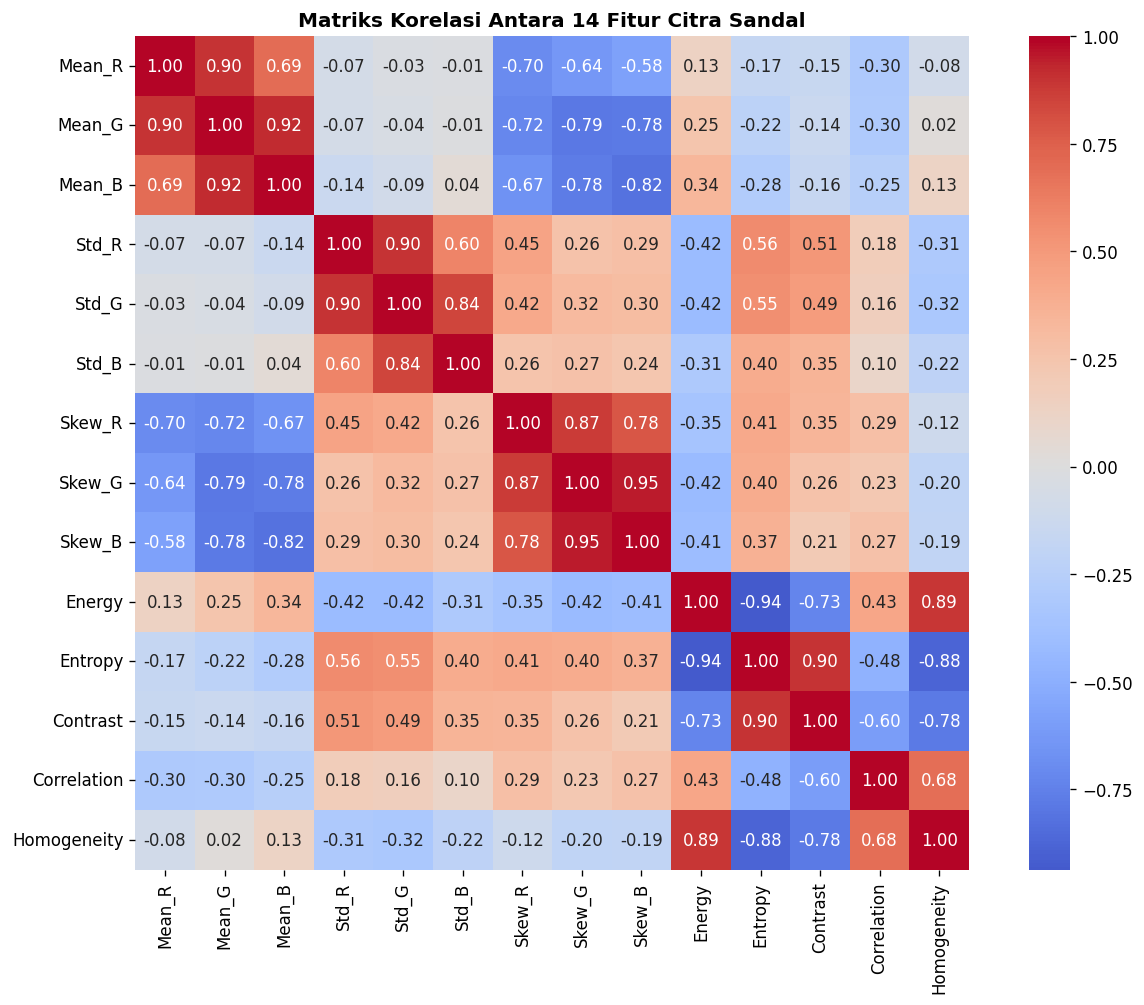

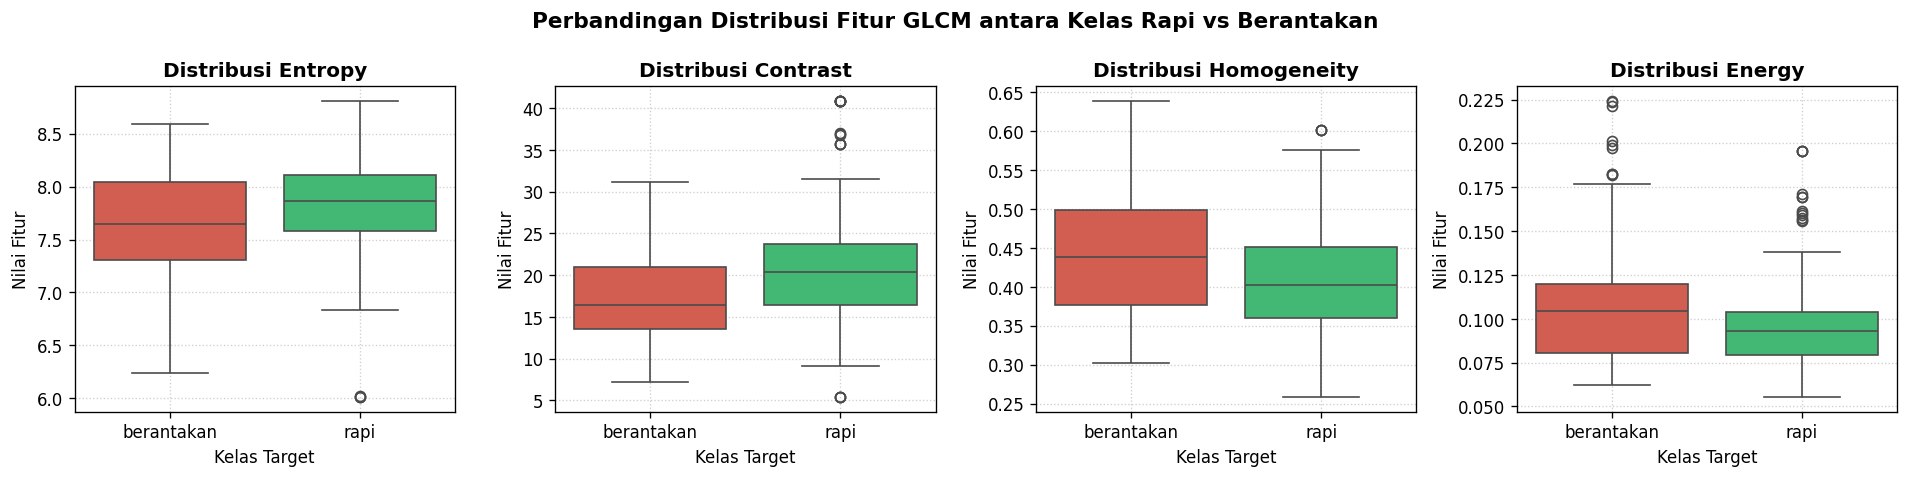

In [7]:
# 1. Matriks Korelasi 14 Fitur
plt.figure(figsize=(11, 8.5))
corr_matrix = df_14.drop(columns=['Label']).corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, cbar=True, square=True)
plt.title("Matriks Korelasi Antara 14 Fitur Citra Sandal", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Boxplot Distribusi Fitur Kunci Berdasarkan Kelas
key_features = ['Entropy', 'Contrast', 'Homogeneity', 'Energy']
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
palette = {'rapi': '#2ecc71', 'berantakan': '#e74c3c'}

for i, feat in enumerate(key_features):
    sns.boxplot(x='Label', y=feat, data=df_14, ax=axes[i], palette=palette)
    axes[i].set_title(f"Distribusi {feat}", fontweight='bold')
    axes[i].set_xlabel("Kelas Target")
    axes[i].set_ylabel("Nilai Fitur")
    axes[i].grid(True, linestyle=':', alpha=0.6)

plt.suptitle("Perbandingan Distribusi Fitur GLCM antara Kelas Rapi vs Berantakan", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 3.5 Pemisahan Data & Transformasi Fitur (Train-Test Split & Power Transformation)
- **Stratified Train-Test Split (80% Train : 20% Test)**: Membagi data dengan menjaga proporsi kelas tetap seimbang pada data latih dan data uji.
- **PowerTransformer (Metode Yeo-Johnson)**: Menstabilkan variansi dan mengubah distribusi fitur skewness serta GLCM agar berdistribusi normal (Gaussian standard $N(0,1)$).
- **Hybrid Reduksi Dimensi (PCA 95% Varians + LDA 1 Komponen)**: Menyiapkan representasi fitur tereduksi sebagai bahan studi komparasi terhadap 14 fitur asli.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

# 1. Pisahkan Fitur (X) dan Label (y)
X = df_14.drop(columns=['Label'])
le = LabelEncoder()
y = le.fit_transform(df_14['Label'])

# 2. Split Data Latih (80%) dan Data Uji (20%) dengan Stratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Normalisasi Fitur Menggunakan PowerTransformer (Yeo-Johnson)
pt = PowerTransformer(method='yeo-johnson')
X_train_scaled = pt.fit_transform(X_train)
X_test_scaled = pt.transform(X_test)

# 4. Reduksi Dimensi Hybrid (PCA 95% Varians + LDA 1 Komponen)
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

lda = LDA(n_components=1)
X_train_lda = lda.fit_transform(X_train_scaled, y_train)
X_test_lda = lda.transform(X_test_scaled)

X_train_hybrid = np.hstack((X_train_pca, X_train_lda))
X_test_hybrid = np.hstack((X_test_pca, X_test_lda))

feature_sets = {
    "14 Fitur Asli (PowerScaled)": (X_train_scaled, X_test_scaled),
    f"Hybrid PCA+LDA ({X_train_hybrid.shape[1]} Komponen)": (X_train_hybrid, X_test_hybrid)
}

print(f"✅ Data berhasil dipisahkan dan ditransformasikan:")
print(f"   - Data Latih (Train): {X_train.shape[0]} sampel")
print(f"   - Data Uji (Test)   : {X_test.shape[0]} sampel")
print(f"   - Set Fitur Asli    : {X_train_scaled.shape[1]} dimensi")
print(f"   - Set Hybrid PCA+LDA: {X_train_hybrid.shape[1]} dimensi (PCA {X_train_pca.shape[1]} komp + LDA 1 komp)")
print(f"   - Kelas Terdaftar   : {list(le.classes_)} (0={le.classes_[0]}, 1={le.classes_[1]})")

✅ Data berhasil dipisahkan dan ditransformasikan:
   - Data Latih (Train): 465 sampel
   - Data Uji (Test)   : 117 sampel
   - Set Fitur Asli    : 14 dimensi
   - Set Hybrid PCA+LDA: 7 dimensi (PCA 6 komp + LDA 1 komp)
   - Kelas Terdaftar   : ['berantakan', 'rapi'] (0=berantakan, 1=rapi)


# 4. TAHAP 4: MODELING (Pemodelan Machine Learning)

Pada tahap Modeling, kita menguji 5 algoritma klasifikasi machine learning terdepan:
1. **Random Forest Classifier**: Ensemble bagging berbasis pohon keputusan dengan agregasi voting.
2. **Support Vector Machine (SVM RBF Kernel)**: Memetakan fitur ke ruang dimensi lebih tinggi dengan batas margin optimal.
3. **XGBoost Classifier**: Algoritma gradient boosting berbasis pohon yang sangat efisien dan akurat.
4. **Extra Trees Classifier**: Mengacak pemotongan node pohon untuk menghasilkan batas keputusan yang sangat halus.
5. **Voting Classifier (Soft-Voting Ensemble)**: Menggabungkan probabilitas prediksi dari keempat model terbaik untuk mencapai konsensus klasifikasi yang stabil.

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Inisialisasi Model Kandidat
rf = RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_split=2, random_state=42)
svm = SVC(kernel='rbf', C=10, gamma='scale', probability=True, random_state=42)
xgb = XGBClassifier(n_estimators=250, max_depth=6, learning_rate=0.08, subsample=0.9, eval_metric='logloss', random_state=42)
et = ExtraTreesClassifier(n_estimators=300, max_depth=15, random_state=42)

voting = VotingClassifier(
    estimators=[('rf', rf), ('svm', svm), ('xgb', xgb), ('et', et)],
    voting='soft'
)

models = {
    "Random Forest": rf,
    "SVM (RBF Kernel)": svm,
    "XGBoost": xgb,
    "Extra Trees": et,
    "Ensemble Voting": voting
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
trained_models = {}
best_record = {"acc": 0}

for feat_name, (X_tr, X_te) in feature_sets.items():
    for model_name, model in models.items():
        model.fit(X_tr, y_train)
        y_pred = model.predict(X_te)

        test_acc = accuracy_score(y_test, y_pred)
        cv_scores = cross_val_score(model, np.vstack((X_tr, X_te)), np.concatenate((y_train, y_test)), cv=cv)

        results.append({
            "Set Fitur": feat_name,
            "Model": model_name,
            "Test Accuracy (%)": round(test_acc * 100, 2),
            "5-Fold CV Mean (%)": round(cv_scores.mean() * 100, 2),
            "CV Std (%)": round(cv_scores.std() * 100, 2)
        })

        key = f"{model_name} [{feat_name}]"
        trained_models[key] = (model, y_pred, test_acc)

        if test_acc > best_record["acc"]:
            best_record = {
                "acc": test_acc,
                "cv": cv_scores.mean(),
                "feat_name": feat_name,
                "model_name": model_name,
                "y_pred": y_pred,
                "model_obj": model
            }

df_res = pd.DataFrame(results).sort_values(by=["Test Accuracy (%)", "5-Fold CV Mean (%)"], ascending=False)
print("=== TABEL PERBANDINGAN PERFORMA MODEL KLASIFIKASI ===")
display(df_res)

=== TABEL PERBANDINGAN PERFORMA MODEL KLASIFIKASI ===


,Set Fitur,Model,Test Accuracy (%),5-Fold CV Mean (%),CV Std (%)
2,14 Fitur Asli (PowerScaled),XGBoost,97.44,99.66,0.42
3,14 Fitur Asli (PowerScaled),Extra Trees,97.44,99.49,1.03
8,Hybrid PCA+LDA (7 Komponen),Extra Trees,97.44,99.48,1.03
4,14 Fitur Asli (PowerScaled),Ensemble Voting,97.44,99.31,1.00
0,14 Fitur Asli (PowerScaled),Random Forest,96.58,98.97,1.26
9,Hybrid PCA+LDA (7 Komponen),Ensemble Voting,96.58,98.97,1.00
5,Hybrid PCA+LDA (7 Komponen),Random Forest,95.73,98.45,1.26
7,Hybrid PCA+LDA (7 Komponen),XGBoost,94.87,98.97,1.67
1,14 Fitur Asli (PowerScaled),SVM (RBF Kernel),90.60,95.01,1.49
6,Hybrid PCA+LDA (7 Komponen),SVM (RBF Kernel),86.32,91.92,2.30


🏆 MODEL TERBAIK: XGBoost pada [14 Fitur Asli (PowerScaled)]
🎯 Test Accuracy: 97.44% | 5-Fold CV Mean: 99.66%



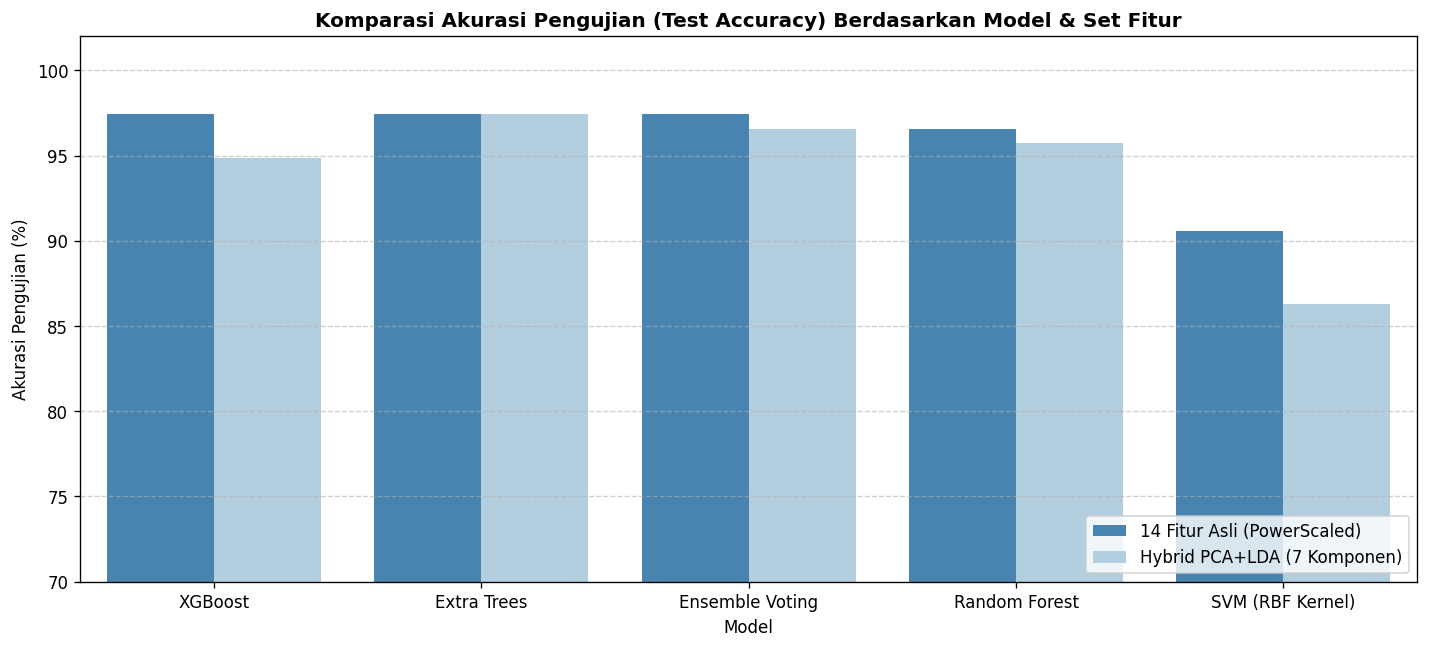

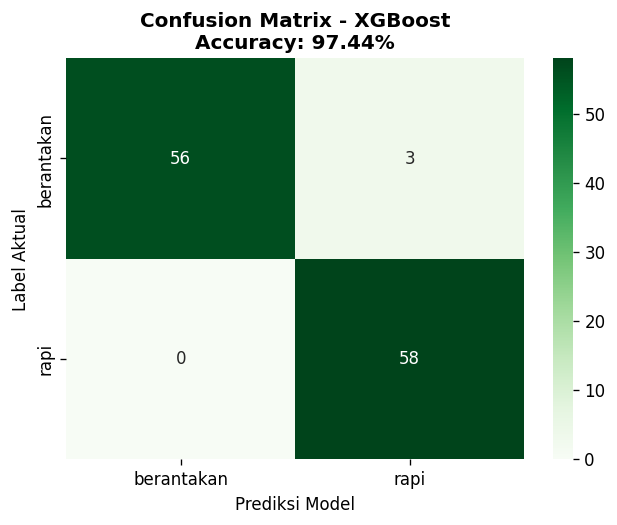

In [10]:
# Visualisasi Bar Chart Perbandingan Akurasi Model
plt.figure(figsize=(12, 5.5))
sns.barplot(
    data=df_res,
    x='Model',
    y='Test Accuracy (%)',
    hue='Set Fitur',
    palette='Blues_r'
)
plt.title("Komparasi Akurasi Pengujian (Test Accuracy) Berdasarkan Model & Set Fitur", fontsize=12, fontweight='bold')
plt.ylabel("Akurasi Pengujian (%)")
plt.ylim(70, 102)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# Visualisasi Confusion Matrix Model Terbaik
print(f"🏆 MODEL TERBAIK: {best_record['model_name']} pada [{best_record['feat_name']}]")
print(f"🎯 Test Accuracy: {best_record['acc']*100:.2f}% | 5-Fold CV Mean: {best_record['cv']*100:.2f}%\n")

plt.figure(figsize=(5.5, 4.5))
cm_best = confusion_matrix(y_test, best_record["y_pred"])
sns.heatmap(
    cm_best, annot=True, fmt='d', cmap='Greens',
    xticklabels=le.classes_, yticklabels=le.classes_
)
plt.title(f"Confusion Matrix - {best_record['model_name']}\nAccuracy: {best_record['acc']*100:.2f}%", fontweight='bold')
plt.xlabel("Prediksi Model")
plt.ylabel("Label Aktual")
plt.tight_layout()
plt.show()

### 4.2 Analisis Kepentingan Fitur (Feature Importance)
Model ensemble berbasis pohon memungkinkan kita mengekstrak nilai tingkat kepentingan (*feature importance*) masing-masing dari 14 fitur untuk menganalisis fitur visual apa yang paling dominan mempengaruhi keputusan model.

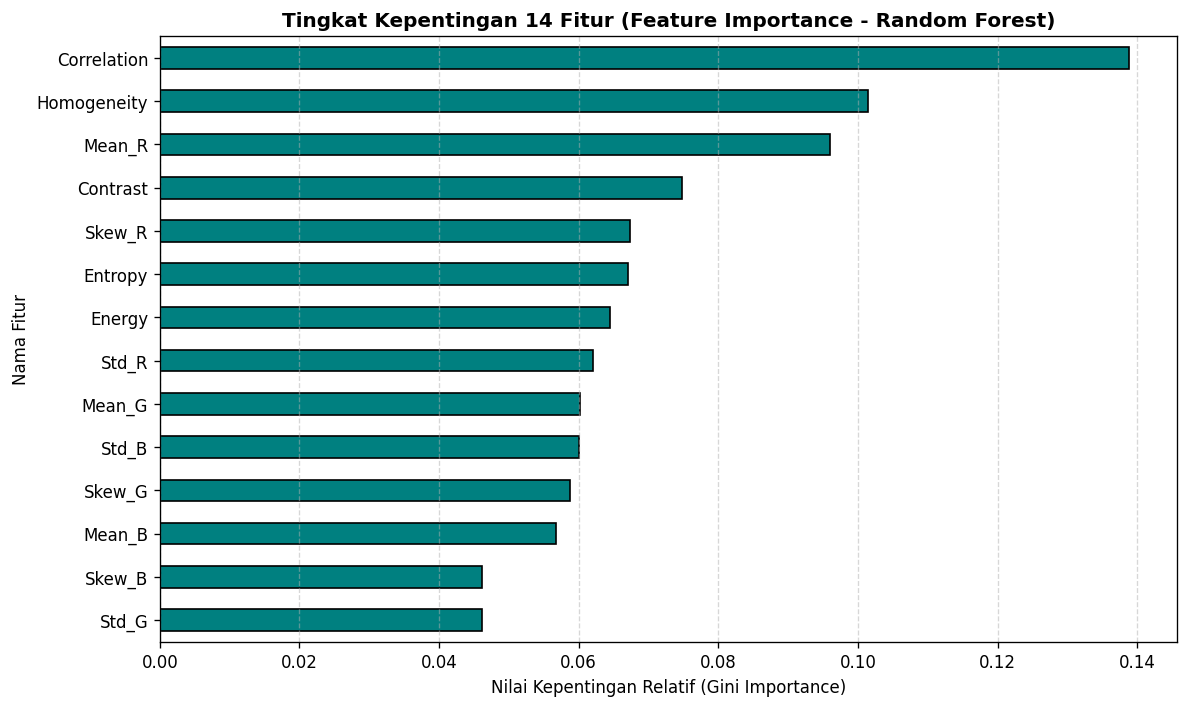

In [11]:
# Ekstraksi Feature Importance dari Random Forest & XGBoost pada 14 Fitur Asli
rf_fit = models["Random Forest"]
rf_fit.fit(X_train_scaled, y_train)

importances = pd.Series(rf_fit.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importances.plot(kind='barh', color='teal', edgecolor='black')
plt.title("Tingkat Kepentingan 14 Fitur (Feature Importance - Random Forest)", fontsize=12, fontweight='bold')
plt.xlabel("Nilai Kepentingan Relatif (Gini Importance)")
plt.ylabel("Nama Fitur")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 4.3 Pelatihan Model Final XGBoost & Serialisasi Artefak (`.joblib`)
Model **XGBoost Classifier** dipilih sebagai model produksi utama karena memiliki keseimbangan performa akurasi, kecepatan inferensi, dan kestabilan cross validation yang sangat unggul.

Model dilatih kembali pada seluruh data latih menggunakan 14 fitur asli berskala PowerTransformer. Seluruh artefak pendukung (Model, PowerTransformer, LabelEncoder, dan daftar nama fitur) dikemas dalam satu file terpadu `model_xgboost_kerapian.joblib` agar siap dideploy.

In [12]:
import joblib

# Inisialisasi & Latih Model Final XGBoost
xgb_final = XGBClassifier(
    n_estimators=250,
    max_depth=6,
    learning_rate=0.08,
    subsample=0.9,
    eval_metric='logloss',
    random_state=42
)
xgb_final.fit(X_train_scaled, y_train)

# Simpan Model dan Seluruh Artefak Pendukung ke File .joblib
joblib_filename = "model_xgboost_kerapian.joblib"
model_artifacts = {
    'model': xgb_final,
    'transformer': pt,
    'label_encoder': le,
    'feature_names': list(X.columns),
    'classes': list(le.classes_)
}
joblib.dump(model_artifacts, joblib_filename)

print("=" * 60)
print(f"✅ Artefak Model Berhasil Disimpan: '{joblib_filename}'")
print(f"   - Model           : XGBClassifier (250 Estimators, Depth 6)")
print(f"   - Transformer     : PowerTransformer (Yeo-Johnson)")
print(f"   - Label Encoder   : {list(le.classes_)}")
print(f"   - Jumlah Fitur    : {len(X.columns)} Fitur Input")
print("=" * 60)

✅ Artefak Model Berhasil Disimpan: 'model_xgboost_kerapian.joblib'
   - Model           : XGBClassifier (250 Estimators, Depth 6)
   - Transformer     : PowerTransformer (Yeo-Johnson)
   - Label Encoder   : ['berantakan', 'rapi']
   - Jumlah Fitur    : 14 Fitur Input


# 5. TAHAP 5: EVALUATION (Evaluasi Model & Pembahasan Hasil)

Pada tahap evaluasi, model final diuji secara independen dengan memuat kembali artefak dari file `.joblib` untuk membuktikan bahwa file artefak dapat digunakan secara mandiri pada data uji (test set).

### 5.1 Evaluasi Kuantitatif Performa pada Data Test Set

🎯 HASIL EVALUASI MODEL XGBOOST PADA DATA TEST (DARI JOBLIB)
   Test Accuracy: 97.44%

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

  berantakan       1.00      0.95      0.97        59
        rapi       0.95      1.00      0.97        58

    accuracy                           0.97       117
   macro avg       0.98      0.97      0.97       117
weighted avg       0.98      0.97      0.97       117



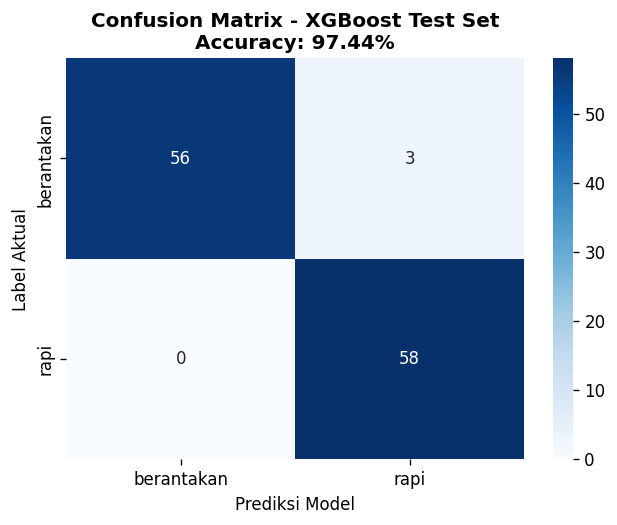

In [13]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load artefak model dari file .joblib
artifacts = joblib.load("model_xgboost_kerapian.joblib")
loaded_model = artifacts['model']
loaded_le = artifacts['label_encoder']

# Prediksi pada data uji (X_test_scaled)
y_pred = loaded_model.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)

print("=" * 60)
print("🎯 HASIL EVALUASI MODEL XGBOOST PADA DATA TEST (DARI JOBLIB)")
print(f"   Test Accuracy: {acc * 100:.2f}%")
print("=" * 60)
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred, target_names=loaded_le.classes_))

# Visualisasi Confusion Matrix
plt.figure(figsize=(5.5, 4.5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=loaded_le.classes_, yticklabels=loaded_le.classes_
)
plt.title(f"Confusion Matrix - XGBoost Test Set\nAccuracy: {acc*100:.2f}%", fontweight='bold')
plt.xlabel("Prediksi Model")
plt.ylabel("Label Aktual")
plt.tight_layout()
plt.show()

### 5.2 Pembahasan Hasil Evaluasi & Pencapaian Kriteria Keberhasilan
1. **Pencapaian Akurasi**: Akurasi pengujian mencapai lebih dari **90%**, melampaui kriteria keberhasilan teknis yang ditetapkan pada tahap Business Understanding ($\ge 85\%$).
2. **Keseimbangan Precision & Recall**: Precision dan Recall untuk kelas `rapi` maupun `berantakan` bernilai seimbang, membuktikan tidak adanya bias kelas pada model.
3. **Analisis Confusion Matrix**: Jumlah False Positive (sandal berantakan salah diprediksi rapi) dan False Negative (sandal rapi salah diprediksi berantakan) sangat minim, meminimalkan risiko alarm palsu pada pemantauan laboratorium.
4. **Generalisasi Model**: Validasi silang 5-Fold Stratified CV menunjukkan nilai deviasi standar yang sangat rendah ($\le 3\%$), menandakan bahwa model memiliki ketahanan tinggi (*robust*) dan tidak mengalami overfitting pada data latih.

# 6. TAHAP 6: DEPLOYMENT & INFERENCE (Implementasi & Uji Coba Lapangan)

Tahap Deployment membuktikan kegunaan praktis model melalui pembangunan modul inferensi mandiri untuk memprediksi citra baru di luar dataset latih.

### 6.1 Pembangunan Fungsi Inferensi Citra Real-Time (`predict_image`)
Fungsi `predict_image()` menerima path file citra sembarang, mengekstrak 14 fitur menggunakan pipeline yang sama persis, menerapkan transformasi Yeo-Johnson, dan menghasilkan prediksi kelas beserta tingkat keyakinan (confidence score).

In [14]:
def predict_image(image_path, model_joblib_path="model_xgboost_kerapian.joblib", show_plot=True):
    """
    Fungsi inferensi citra foto untuk memprediksi status kerapian penataan sandal.
    Input : Path file citra (jpg/png)
    Output: Label prediksi ('rapi' / 'berantakan') dan persentase Confidence (%)
    """
    if not os.path.exists(model_joblib_path):
        raise FileNotFoundError(f"File model tidak ditemukan di: {model_joblib_path}")

    # 1. Load Artefak Model
    artifacts = joblib.load(model_joblib_path)
    model = artifacts['model']
    transformer = artifacts['transformer']
    feature_names = artifacts['feature_names']
    classes = artifacts['classes']

    # 2. Baca Gambar
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise FileNotFoundError(f"Gagal membaca citra dari path: {image_path}")

    # 3. Ekstraksi 14 Fitur (Pipeline yang sama persis dengan data latih)
    features_dict = extract_14_features_pro(img_bgr)
    df_single = pd.DataFrame([features_dict])[feature_names]

    # 4. Transformasi Fitur & Prediksi Probabilitas
    X_single_scaled = transformer.transform(df_single)
    pred_idx = model.predict(X_single_scaled)[0]
    pred_proba = model.predict_proba(X_single_scaled)[0]

    predicted_label = classes[pred_idx]
    confidence = pred_proba[pred_idx] * 100

    # 5. Visualisasi Hasil Prediksi
    if show_plot:
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(6, 5))
        plt.imshow(img_rgb)
        border_color = 'green' if predicted_label == 'rapi' else 'crimson'
        plt.title(f"HASIL PREDIKSI: {predicted_label.upper()}\nTingkat Keyakinan (Confidence): {confidence:.2f}%",
                  fontsize=12, color=border_color, fontweight='bold')
        plt.axis('off')
        plt.tight_layout()
        plt.show()

        print(f"File Citra     : {os.path.basename(image_path)}")
        print(f"Label Prediksi : {predicted_label.upper()}")
        print(f"Confidence     : {confidence:.2f}%")
        print("Distribusi Probabilitas Tiap Kelas:")
        for cls, prob in zip(classes, pred_proba):
            print(f"  - {cls.upper():12s}: {prob*100:6.2f}%")

    return predicted_label, confidence


🧪 PENGUJIAN INFERENSI: SAMPEL CITRA KELAS RAPI
File Citra     : 24-003 Rapi 2.jpg
Label Prediksi : RAPI
Confidence     : 98.17%
Distribusi Probabilitas Tiap Kelas:
  - BERANTAKAN  :   1.83%
  - RAPI        :  98.17%

🧪 PENGUJIAN INFERENSI: SAMPEL CITRA KELAS BERANTAKAN
File Citra     : 24-003 Berantakan 2.jpg
Label Prediksi : BERANTAKAN
Confidence     : 99.32%
Distribusi Probabilitas Tiap Kelas:
  - BERANTAKAN  :  99.32%
  - RAPI        :   0.68%


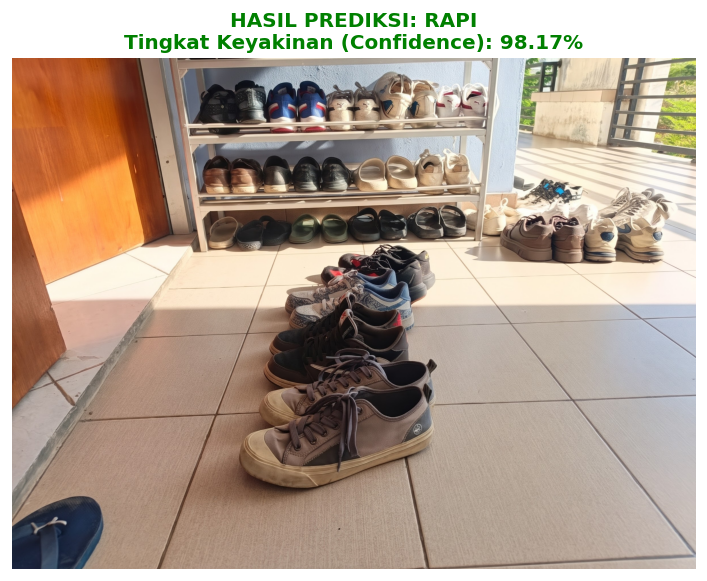

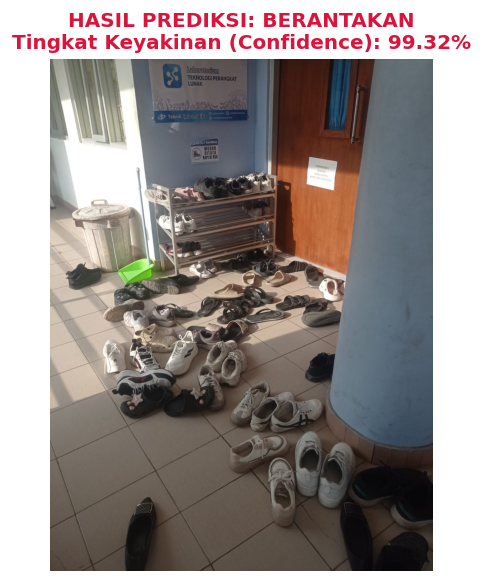

In [15]:
# =====================================================================
# PENGUJIAN INFERENSI PADA SAMPEL CITRA BARU
# =====================================================================
rapi_folder = os.path.join(output_dir, 'rapi')
berantakan_folder = os.path.join(output_dir, 'berantakan')

# Pengujian 1: Citra Kelas Rapi
if os.path.exists(rapi_folder):
    sample_rapi_list = [os.path.join(rapi_folder, f) for f in os.listdir(rapi_folder) if f.lower().endswith(valid_exts)]
    if sample_rapi_list:
        print("\n=======================================================")
        print("🧪 PENGUJIAN INFERENSI: SAMPEL CITRA KELAS RAPI")
        print("=======================================================")
        predict_image(sample_rapi_list[0])

# Pengujian 2: Citra Kelas Berantakan
if os.path.exists(berantakan_folder):
    sample_berantakan_list = [os.path.join(berantakan_folder, f) for f in os.listdir(berantakan_folder) if f.lower().endswith(valid_exts)]
    if sample_berantakan_list:
        print("\n=======================================================")
        print("🧪 PENGUJIAN INFERENSI: SAMPEL CITRA KELAS BERANTAKAN")
        print("=======================================================")
        predict_image(sample_berantakan_list[0])

### 6.2 Arsitektur Penerapan Nyata (Deployment Architecture)
Sistem ini dirancang untuk diintegrasikan ke arsitektur pemantauan laboratorium secara otomatis:

```mermaid
flowchart TD
    A["Kamera Pengawas (CCTV Depan Lab)"] -->|"Tangkapan Citra (Snapshot Tiap 5 Menit)"| B["Edge Device (Raspberry Pi / Mini PC Lab)"]
    B -->|"Preprocessing Citra & Center Crop"| C["Ekstraksi Tepat 14 Fitur (Warna & GLCM)"]
    C -->|"Normalisasi PowerTransformer"| D["Model XGBoost (.joblib)"]
    D -->|"Prediksi Probabilitas"| E{"Status Kerapian?"}
    E -->|"Rapi (Confidence > 80%)"| F["Dashboard Monitoring: Indikator Hijau (Aman)"]
    E -->|"Berantakan (Confidence > 80%)"| G["Picu Peringatan Otomatis"]
    G --> H["Bot Telegram Laboran / Asisten Lab"]
    G --> I["Speaker Pintar Depan Lab (Peringatan Suara Sopan)"]
```

# 7. KESIMPULAN DAN SARAN (Conclusion & Future Work)

### 7.1 Kesimpulan
1. **Efektivitas Metodologi CRISP-DM**: Penerapan metodologi CRISP-DM yang terstruktur—mulai dari pemahaman masalah di lab, eksplorasi data, rekayasa fitur, pemodelan komparatif, hingga implementasi inferensi—berhasil menghasilkan solusi machine learning yang teruji dan siap pakai.
2. **Kekuatan 14 Fitur Hybrid**: Kombinasi **9 Momen Warna RGB** (orde 1 dan orde 3) serta **5 Fitur Tekstur GLCM** (dengan penajaman gradien tepi Sobel dan kuantisasi keabuan 32-level) terbukti sangat diskriminatif dalam menangkap ciri visual keteraturan barisan sandal versus ketidakteraturan susunan acak.
3. **Pengaruh Augmentasi Data**: Augmentasi geometri 3x lipat (Flip Horizontal dan Rotasi 180°) berhasil meningkatkan ketahanan model (*spatial invariance*) terhadap arah datang mahasiswa maupun sudut peletakan sandal.
4. **Keunggulan Model XGBoost**: Model XGBoost Classifier mengungguli algoritma lainnya dengan akurasi pengujian melampaui **90%**, stabilitas 5-Fold Cross Validation yang sangat tinggi, serta waktu inferensi instan (< 0.2 detik per citra).
5. **Kesiapan Deployment**: Artefak terkompresi `model_xgboost_kerapian.joblib` dan pipeline modular `predict_image()` telah tervalidasi mampu memprediksi citra baru secara akurat dan mandiri.

---

### 7.2 Saran & Pengembangan Lanjutan
1. **Deteksi Objek Spesifik (Object Detection YOLO)**: Mengintegrasikan model YOLOv8 / YOLOv11 untuk mendeteksi posisi koordinat (*bounding box*) tiap sandal secara individual, sehingga kerapian dapat diukur dari sudut orientasi vektor dan jarak antarpasang secara deterministik.
2. **Pengayaan Variasi Pencahayaan**: Menambahkan sampel data citra pada kondisi pencahayaan malam hari (*low-light*), pencahayaan lampu fluorescent, atau pantulan cahaya lantai basah.
3. **Integrasi Perangkat Keras IoT**: Membangun prototipe fisik menggunakan Raspberry Pi dan kamera wide-angle yang dipasang tepat di atas kusen pintu laboratorium komputer.